# 05 - تقسيم الصور والعمليات المورفولوجية وعزل العناصر

**المشروع:** Vision Studio - معالجة الصور والرؤية بالحاسوب  
**المقرر:** معالجة الصور والرؤية بالحاسوب - بكالوريوس ذكاء اصطناعي  
**إشراف:** الدكتورة سمية الشيبة

يعتمد هذا الدفتر على موضوعات **LAB 9 - Image Segmentation** في المحاضرات، ويوسعها بوظائف عملية يحتاجها تطبيق Android مثل تنظيف الأقنعة، اكتشاف العناصر، عزل أكبر عنصر وإزالة الخلفية البسيطة.

## أهداف الدفتر

بعد تنفيذ الدفتر ستتمكن من:

1. تطبيق الأنواع الأساسية من Thresholding ومقارنتها.
2. استخدام Otsu لاختيار العتبة تلقائيًا.
3. معالجة اختلاف الإضاءة باستخدام Adaptive Thresholding.
4. عزل الألوان في فضاء HSV.
5. تقسيم ألوان الصورة باستخدام K-Means.
6. تنظيف الأقنعة باستخدام Erosion وDilation وOpening وClosing.
7. اكتشاف العناصر ورسم Contours وBounding Boxes.
8. عزل أكبر عنصر وإزالة الخلفية باستخدام GrabCut.
9. حفظ نتائج جميع الصور في Google Drive دون إعادة رفع الصور.

> لتقليل استهلاك الإنترنت، يقرأ الدفتر الصور المحفوظة سابقًا في Drive. اترك `UPLOAD_NEW_FILES = False` إلا عند إضافة صور جديدة.

## 1. استيراد المكتبات وربط Google Drive

In [1]:
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
    PROJECT_ROOT = Path(
        '/content/drive/MyDrive/'
        'VisionStudio_Android_ImageProcessing'
    )
except ImportError:
    IN_COLAB = False
    PROJECT_ROOT = Path('VisionStudio_Android_ImageProcessing')

INPUT_DIR = PROJECT_ROOT / '02_Data/Images/Input'
OUTPUT_DIR = (
    PROJECT_ROOT
    / '04_Outputs/Images/05_Image_Segmentation_Morphology'
)

INPUT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print('Running in Colab:', IN_COLAB)
print('Input directory:', INPUT_DIR)
print('Output directory:', OUTPUT_DIR)

Mounted at /content/drive
Running in Colab: True
Input directory: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/02_Data/Images/Input
Output directory: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/04_Outputs/Images/05_Image_Segmentation_Morphology


## 2. دوال العرض والتحقق

In [2]:
def to_rgb(image):
    if image.ndim == 2:
        return image
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


def show_comparison(results, columns=3, figure_width=16):
    items = list(results.items())
    rows = int(np.ceil(len(items) / columns))
    fig, axes = plt.subplots(
        rows, columns,
        figsize=(figure_width, rows * 4.5),
        squeeze=False
    )

    for axis, (title, result) in zip(axes.ravel(), items):
        axis.imshow(
            to_rgb(result),
            cmap='gray' if result.ndim == 2 else None
        )
        axis.set_title(title)
        axis.axis('off')

    for axis in axes.ravel()[len(items):]:
        axis.axis('off')

    plt.tight_layout()
    plt.show()


def valid_odd_number(value, minimum=3):
    value = max(int(value), int(minimum))
    if value % 2 == 0:
        value += 1
    return value


def create_structuring_element(kernel_size=5, shape='ellipse'):
    k = valid_odd_number(kernel_size, minimum=1)
    shapes = {
        'rectangle': cv2.MORPH_RECT,
        'ellipse': cv2.MORPH_ELLIPSE,
        'cross': cv2.MORPH_CROSS
    }
    return cv2.getStructuringElement(shapes.get(shape, cv2.MORPH_ELLIPSE), (k, k))

## 3. دوال Thresholding والتقسيم

In [3]:
def threshold_variants(image, threshold_value=127):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    threshold_value = int(np.clip(threshold_value, 0, 255))

    variants = {'Grayscale': gray}
    threshold_types = {
        'Binary': cv2.THRESH_BINARY,
        'Binary Inverse': cv2.THRESH_BINARY_INV,
        'Truncate': cv2.THRESH_TRUNC,
        'To Zero': cv2.THRESH_TOZERO,
        'To Zero Inverse': cv2.THRESH_TOZERO_INV
    }

    for name, threshold_type in threshold_types.items():
        _, result = cv2.threshold(
            gray, threshold_value, 255, threshold_type
        )
        variants[name] = result

    return variants


def otsu_threshold(image, invert=False):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    threshold_type = cv2.THRESH_BINARY_INV if invert else cv2.THRESH_BINARY
    otsu_value, result = cv2.threshold(
        gray, 0, 255, threshold_type + cv2.THRESH_OTSU
    )
    return otsu_value, result


def adaptive_thresholds(image, block_size=11, constant=2):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    block = valid_odd_number(block_size, minimum=3)
    blurred = cv2.GaussianBlur(gray, (3, 3), 0)

    adaptive_mean = cv2.adaptiveThreshold(
        blurred, 255,
        cv2.ADAPTIVE_THRESH_MEAN_C,
        cv2.THRESH_BINARY,
        block, float(constant)
    )
    adaptive_gaussian = cv2.adaptiveThreshold(
        blurred, 255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY,
        block, float(constant)
    )
    return adaptive_mean, adaptive_gaussian


def hsv_color_mask(
    image,
    lower_hsv=(0, 70, 50),
    upper_hsv=(20, 255, 255)
):
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    lower = np.array(lower_hsv, dtype=np.uint8)
    upper = np.array(upper_hsv, dtype=np.uint8)
    mask = cv2.inRange(hsv, lower, upper)
    result = cv2.bitwise_and(image, image, mask=mask)
    return mask, result


def kmeans_segmentation(image, clusters=3, max_pixels=350000):
    clusters = max(2, int(clusters))
    height, width = image.shape[:2]
    pixel_count = height * width

    if pixel_count > max_pixels:
        scale = np.sqrt(max_pixels / pixel_count)
        work_image = cv2.resize(
            image, None, fx=scale, fy=scale,
            interpolation=cv2.INTER_AREA
        )
    else:
        work_image = image.copy()

    pixels = np.float32(work_image.reshape((-1, 3)))
    criteria = (
        cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER,
        20,
        1.0
    )
    cv2.setRNGSeed(42)
    _, labels, centers = cv2.kmeans(
        pixels, clusters, None, criteria, 5,
        cv2.KMEANS_PP_CENTERS
    )

    centers = np.uint8(centers)
    segmented_small = centers[labels.flatten()].reshape(work_image.shape)

    if segmented_small.shape[:2] != (height, width):
        return cv2.resize(
            segmented_small, (width, height),
            interpolation=cv2.INTER_NEAREST
        )
    return segmented_small

## 4. دوال العمليات المورفولوجية واكتشاف العناصر

In [4]:
def prepare_foreground_mask(image):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)
    _, mask = cv2.threshold(
        blurred, 0, 255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    # نجعل الجزء الأقل مساحة هو المقدمة غالبًا، لمنع الخلفية من أن تصبح عنصرًا.
    if cv2.countNonZero(mask) > mask.size / 2:
        mask = cv2.bitwise_not(mask)

    kernel = create_structuring_element(5, 'ellipse')
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
    return mask


def morphology_results(mask, kernel_size=5, iterations=1, shape='ellipse'):
    kernel = create_structuring_element(kernel_size, shape)
    iterations = max(1, int(iterations))
    return {
        'Erosion': cv2.erode(mask, kernel, iterations=iterations),
        'Dilation': cv2.dilate(mask, kernel, iterations=iterations),
        'Opening': cv2.morphologyEx(
            mask, cv2.MORPH_OPEN, kernel, iterations=iterations
        ),
        'Closing': cv2.morphologyEx(
            mask, cv2.MORPH_CLOSE, kernel, iterations=iterations
        ),
        'Morphological Gradient': cv2.morphologyEx(
            mask, cv2.MORPH_GRADIENT, kernel, iterations=iterations
        )
    }


def detect_contours(image, mask=None, minimum_area=500):
    if mask is None:
        mask = prepare_foreground_mask(image)

    contours, _ = cv2.findContours(
        mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    valid_contours = [
        contour for contour in contours
        if cv2.contourArea(contour) >= float(minimum_area)
    ]

    result = image.copy()
    cv2.drawContours(result, valid_contours, -1, (0, 255, 0), 2)
    for index, contour in enumerate(valid_contours, start=1):
        x, y, width, height = cv2.boundingRect(contour)
        cv2.rectangle(
            result, (x, y), (x + width, y + height),
            (0, 0, 255), 2
        )
        cv2.putText(
            result, str(index), (x, max(20, y - 8)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.6,
            (255, 0, 0), 2, cv2.LINE_AA
        )

    return result, len(valid_contours), mask, valid_contours


def isolate_largest_object(image, mask=None):
    if mask is None:
        mask = prepare_foreground_mask(image)

    contours, _ = cv2.findContours(
        mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    if not contours:
        return np.zeros_like(image), np.zeros_like(mask), 0.0

    largest = max(contours, key=cv2.contourArea)
    object_mask = np.zeros_like(mask)
    cv2.drawContours(object_mask, [largest], -1, 255, thickness=-1)
    isolated = cv2.bitwise_and(image, image, mask=object_mask)
    return isolated, object_mask, float(cv2.contourArea(largest))


def grabcut_foreground(image, margin_ratio=0.05, iterations=3):
    height, width = image.shape[:2]
    margin_x = max(1, int(width * float(margin_ratio)))
    margin_y = max(1, int(height * float(margin_ratio)))
    rect_width = max(1, width - 2 * margin_x)
    rect_height = max(1, height - 2 * margin_y)
    rectangle = (margin_x, margin_y, rect_width, rect_height)

    grabcut_mask = np.zeros((height, width), dtype=np.uint8)
    background_model = np.zeros((1, 65), dtype=np.float64)
    foreground_model = np.zeros((1, 65), dtype=np.float64)

    cv2.grabCut(
        image, grabcut_mask, rectangle,
        background_model, foreground_model,
        max(1, int(iterations)), cv2.GC_INIT_WITH_RECT
    )

    foreground_mask = np.where(
        (grabcut_mask == cv2.GC_FGD)
        | (grabcut_mask == cv2.GC_PR_FGD),
        255, 0
    ).astype(np.uint8)
    foreground = cv2.bitwise_and(image, image, mask=foreground_mask)
    return foreground, foreground_mask

## 5. قراءة الصور الموجودة أو رفع صور جديدة اختياريًا

- التشغيل المعتاد: اترك `UPLOAD_NEW_FILES = False`.
- لإضافة صورة جديدة فقط: غيّرها مؤقتًا إلى `True`، نفّذ الخلية، ثم أعدها إلى `False`.
- إذا كان المجلد فارغًا، ينشئ الدفتر صورة اختبار صغيرة تلقائيًا.

In [5]:
UPLOAD_NEW_FILES = False
SUPPORTED_EXTENSIONS = {
    '.jpg', '.jpeg', '.png', '.bmp',
    '.tif', '.tiff', '.webp'
}


def load_images_from_directory(directory):
    images = {}
    for path in sorted(directory.iterdir()):
        if not path.is_file() or path.suffix.lower() not in SUPPORTED_EXTENSIONS:
            continue
        loaded = cv2.imread(str(path), cv2.IMREAD_COLOR)
        if loaded is None:
            print(f'تعذر قراءة الملف: {path.name}')
            continue
        images[path.name] = loaded
    return images


uploaded_images = load_images_from_directory(INPUT_DIR)

if IN_COLAB and UPLOAD_NEW_FILES:
    from google.colab import files

    new_files = files.upload()
    for file_name, file_data in new_files.items():
        image_array = np.frombuffer(file_data, dtype=np.uint8)
        loaded_image = cv2.imdecode(image_array, cv2.IMREAD_COLOR)

        if loaded_image is None:
            print(f'تعذر قراءة الملف: {file_name}')
            continue

        safe_name = Path(file_name).name
        save_path = INPUT_DIR / safe_name
        if not cv2.imwrite(str(save_path), loaded_image):
            raise IOError(f'فشل حفظ الصورة: {save_path}')
        uploaded_images[safe_name] = loaded_image

if not uploaded_images:
    height, width = 520, 800
    generated = np.full((height, width, 3), 235, dtype=np.uint8)
    illumination = np.tile(
        np.linspace(0, 45, width, dtype=np.uint8),
        (height, 1)
    )
    generated = cv2.subtract(
        generated, cv2.merge([illumination] * 3)
    )
    cv2.circle(generated, (180, 180), 95, (30, 30, 220), -1)
    cv2.rectangle(generated, (350, 80), (650, 260), (40, 190, 40), -1)
    triangle = np.array([[300, 430], [470, 300], [610, 450]], np.int32)
    cv2.fillPoly(generated, [triangle], (220, 80, 30))
    cv2.putText(
        generated, 'SEGMENT', (70, 490),
        cv2.FONT_HERSHEY_SIMPLEX, 1.2,
        (40, 40, 40), 3, cv2.LINE_AA
    )
    generated_name = 'segmentation_test.png'
    generated_path = INPUT_DIR / generated_name
    if not cv2.imwrite(str(generated_path), generated):
        raise IOError(f'فشل حفظ صورة الاختبار: {generated_path}')
    uploaded_images[generated_name] = generated
    print('لم توجد صور؛ تم إنشاء صورة اختبار تلقائيًا.')

print(f'عدد الصور المتاحة: {len(uploaded_images)}')
for name, loaded_image in uploaded_images.items():
    image_height, image_width = loaded_image.shape[:2]
    print(f'- {name}: {image_width} x {image_height}')

عدد الصور المتاحة: 4
- R.jpeg: 736 x 736
- balloons.jpg: 602 x 547
- children.jpeg: 1376 x 774
- coins.jpg: 400 x 390


## 6. اختيار صورة العرض

Selected image: R.jpeg
Shape: (736, 736, 3)
Data type: uint8


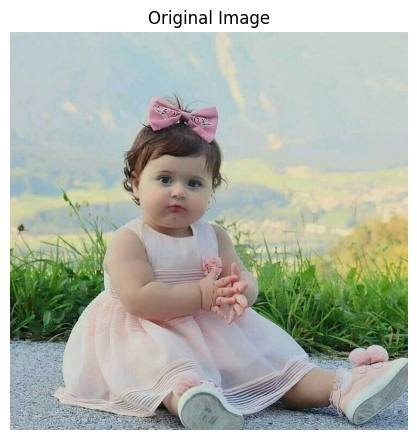

In [6]:
# اتركه فارغًا لاختيار أول صورة، أو اكتب اسم الملف كاملًا.
SELECTED_IMAGE_NAME = ''

if SELECTED_IMAGE_NAME:
    if SELECTED_IMAGE_NAME not in uploaded_images:
        available = ', '.join(uploaded_images.keys())
        raise ValueError(
            f'الصورة غير موجودة. الصور المتاحة: {available}'
        )
    selected_name = SELECTED_IMAGE_NAME
else:
    selected_name = next(iter(uploaded_images))

image = uploaded_images[selected_name]

print('Selected image:', selected_name)
print('Shape:', image.shape)
print('Data type:', image.dtype)
show_comparison({'Original Image': image}, columns=1, figure_width=8)

## 7. مقارنة أنواع Thresholding

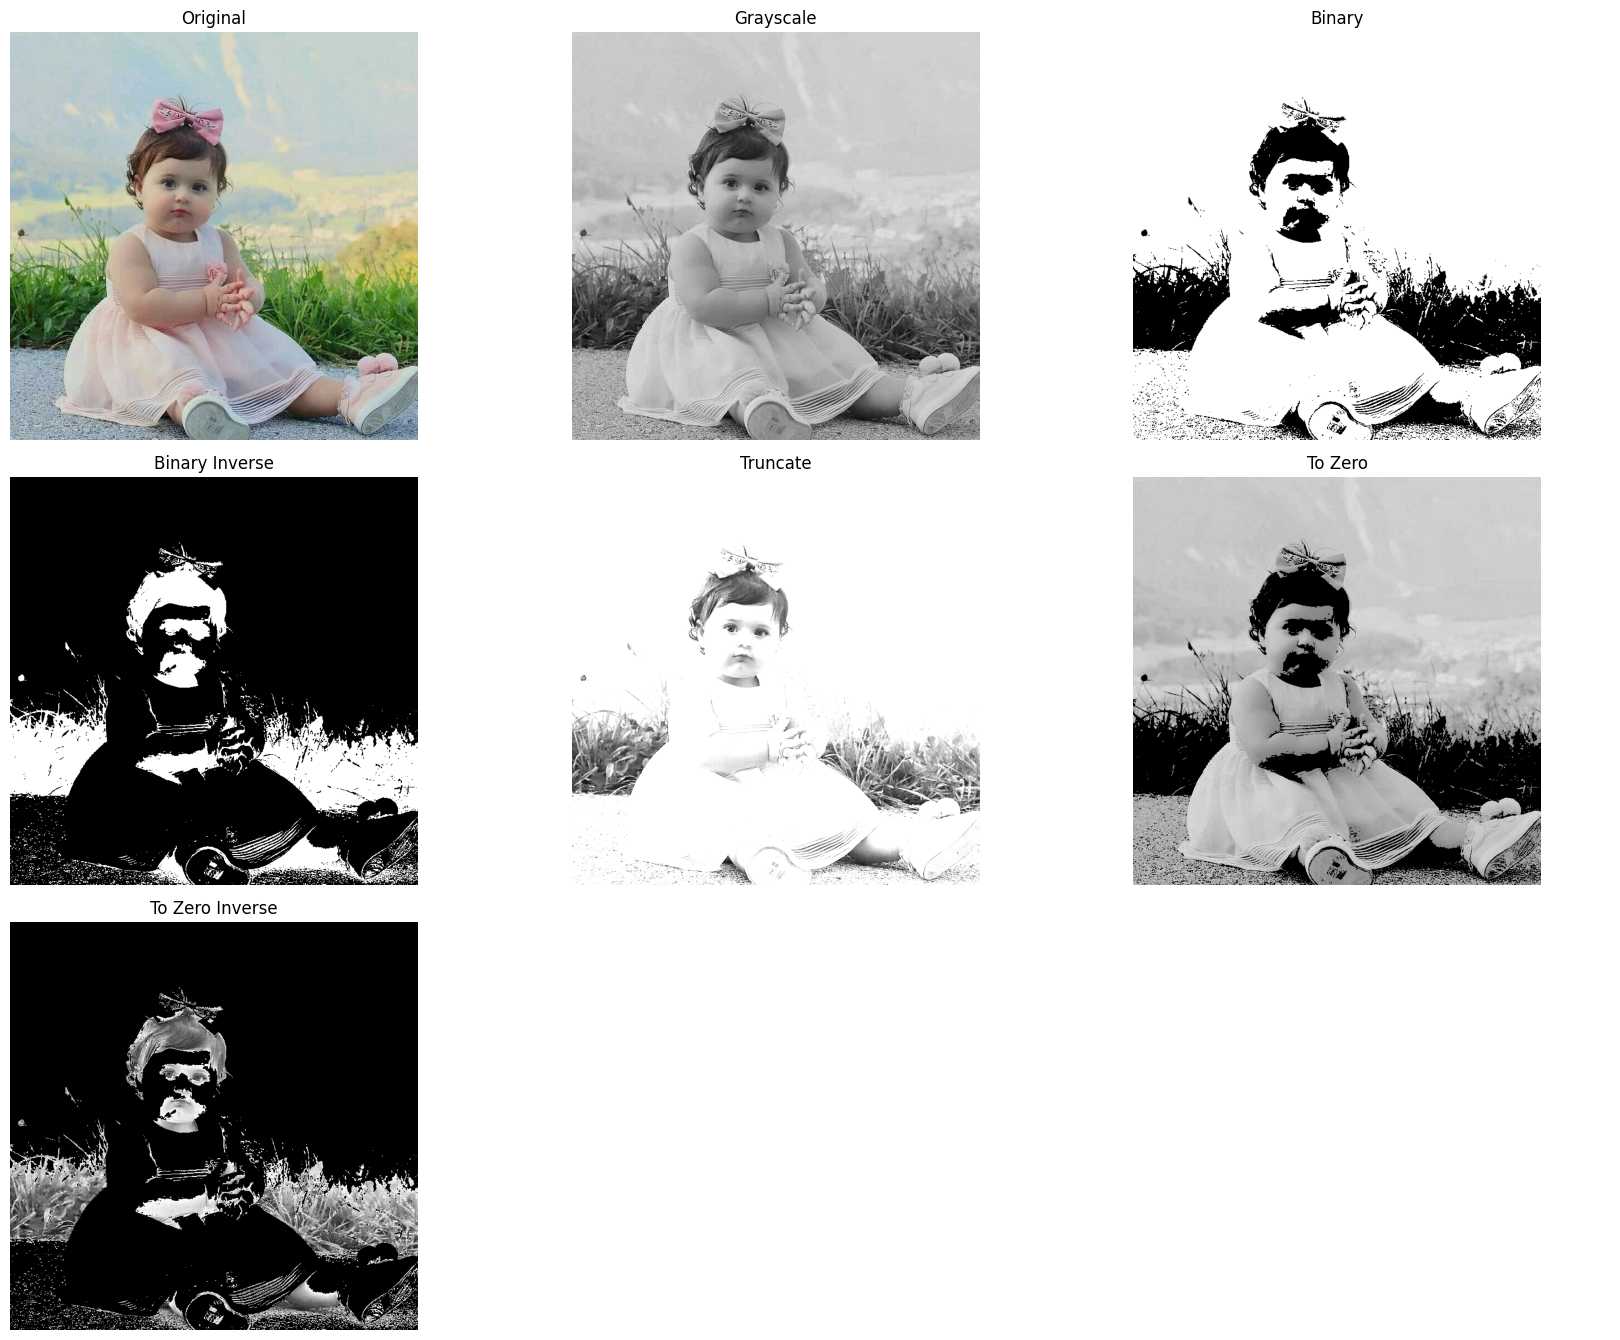

In [7]:
threshold_results = {'Original': image}
threshold_results.update(threshold_variants(image, threshold_value=127))

show_comparison(
    threshold_results,
    columns=3,
    figure_width=17
)

### الفرق بين طرق Thresholding

| النوع | النتيجة |
|---|---|
| Binary | القيم الأكبر من العتبة تصبح 255 والباقي 0 |
| Binary Inverse | عكس Binary |
| Truncate | القيم الأكبر من العتبة تُستبدل بقيمة العتبة |
| To Zero | القيم الأقل من العتبة تصبح صفرًا |
| To Zero Inverse | القيم الأعلى من العتبة تصبح صفرًا |

العتبة الواحدة مناسبة عندما تكون الإضاءة متقاربة. أما الصور ذات الإضاءة غير المتساوية فتستفيد عادة من Adaptive Thresholding.

## 8. مقارنة العتبة العادية وOtsu وAdaptive Thresholding

Otsu selected threshold: 143.00


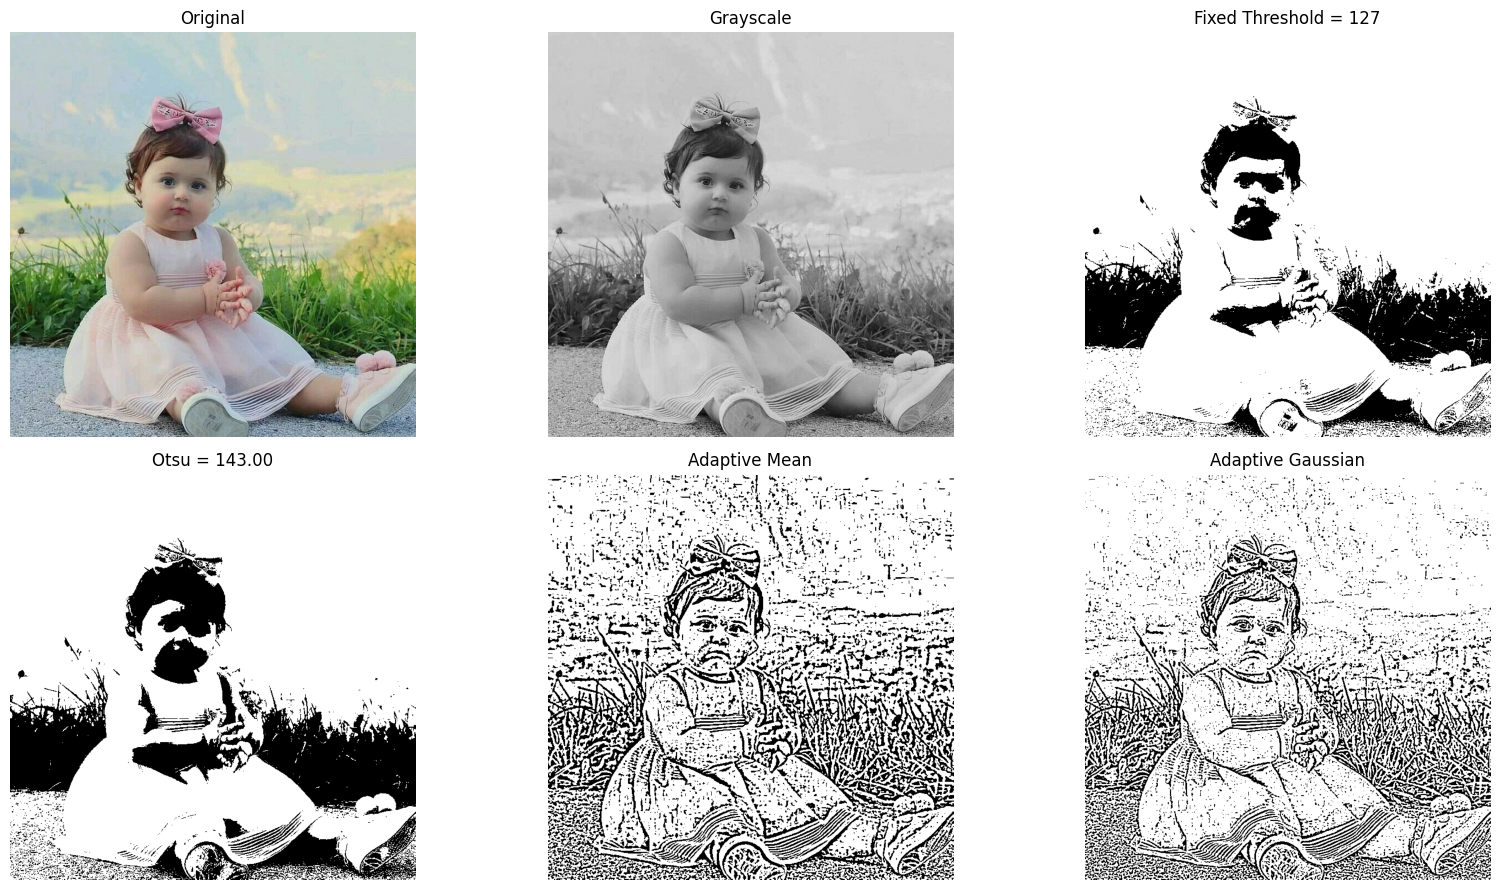

In [8]:
gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
_, fixed_binary = cv2.threshold(gray_image, 127, 255, cv2.THRESH_BINARY)
otsu_value, otsu_result = otsu_threshold(image)
adaptive_mean, adaptive_gaussian = adaptive_thresholds(
    image, block_size=11, constant=2
)

print(f'Otsu selected threshold: {otsu_value:.2f}')

show_comparison(
    {
        'Original': image,
        'Grayscale': gray_image,
        'Fixed Threshold = 127': fixed_binary,
        f'Otsu = {otsu_value:.2f}': otsu_result,
        'Adaptive Mean': adaptive_mean,
        'Adaptive Gaussian': adaptive_gaussian
    },
    columns=3,
    figure_width=17
)

## 9. أداة Thresholding التفاعلية

In [9]:
try:
    import ipywidgets as widgets
    from IPython.display import display
    WIDGETS_AVAILABLE = True
except ImportError:
    WIDGETS_AVAILABLE = False
    print('الأدوات التفاعلية متاحة تلقائيًا داخل Google Colab.')


def interactive_threshold(
    method='Fixed Binary', threshold_value=127,
    block_size=11, constant=2
):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    if method == 'Fixed Binary':
        _, result = cv2.threshold(
            gray, int(threshold_value), 255, cv2.THRESH_BINARY
        )
        title = f'Fixed Threshold = {int(threshold_value)}'
    elif method == 'Otsu':
        selected_value, result = otsu_threshold(image)
        title = f'Otsu Threshold = {selected_value:.2f}'
    else:
        mean_result, gaussian_result = adaptive_thresholds(
            image, block_size, constant
        )
        if method == 'Adaptive Mean':
            result = mean_result
        else:
            result = gaussian_result
        title = (
            f'{method}: block={valid_odd_number(block_size)}, '
            f'C={constant}'
        )

    show_comparison(
        {'Original': image, title: result},
        columns=2,
        figure_width=12
    )


if WIDGETS_AVAILABLE:
    threshold_controls = widgets.interactive(
        interactive_threshold,
        method=widgets.Dropdown(
            options=[
                'Fixed Binary', 'Otsu',
                'Adaptive Mean', 'Adaptive Gaussian'
            ],
            value='Fixed Binary', description='Method'
        ),
        threshold_value=widgets.IntSlider(
            value=127, min=0, max=255, step=1,
            description='Threshold'
        ),
        block_size=widgets.IntSlider(
            value=11, min=3, max=51, step=2,
            description='Block'
        ),
        constant=widgets.IntSlider(
            value=2, min=-20, max=20, step=1,
            description='C'
        )
    )
    display(threshold_controls)
else:
    interactive_threshold()

interactive(children=(Dropdown(description='Method', options=('Fixed Binary', 'Otsu', 'Adaptive Mean', 'Adapti…

## 10. عزل الألوان باستخدام HSV وتقسيم K-Means

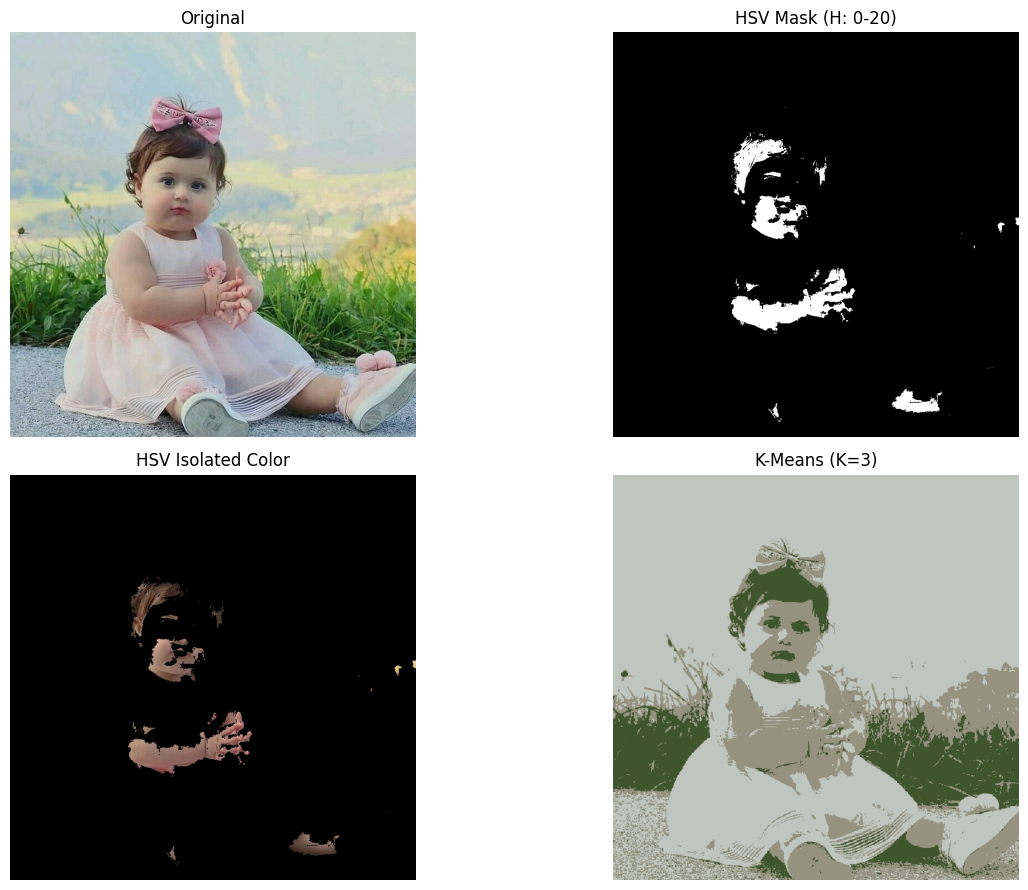

In [10]:
hsv_mask, hsv_isolated = hsv_color_mask(
    image,
    lower_hsv=(0, 70, 50),
    upper_hsv=(20, 255, 255)
)
kmeans_result = kmeans_segmentation(image, clusters=3)

show_comparison(
    {
        'Original': image,
        'HSV Mask (H: 0-20)': hsv_mask,
        'HSV Isolated Color': hsv_isolated,
        'K-Means (K=3)': kmeans_result
    },
    columns=2,
    figure_width=14
)

### لماذا نستخدم HSV؟

في BGR تكون معلومات اللون والإضاءة مختلطة. في HSV يمكن تحديد:

- `H`: نوع اللون من 0 إلى 179 في OpenCV.
- `S`: تشبع اللون من 0 إلى 255.
- `V`: شدة الإضاءة من 0 إلى 255.

أما K-Means فيجمع البكسلات ذات الألوان المتقاربة في `K` مجموعات، ولا يحتاج إلى تحديد لون مسبقًا.

## 11. أداة HSV وK-Means التفاعلية

In [11]:
def interactive_color_segmentation(
    method='HSV', h_low=0, h_high=20,
    s_low=70, v_low=50, clusters=3
):
    if method == 'HSV':
        low_h = min(int(h_low), int(h_high))
        high_h = max(int(h_low), int(h_high))
        mask, result = hsv_color_mask(
            image,
            lower_hsv=(low_h, int(s_low), int(v_low)),
            upper_hsv=(high_h, 255, 255)
        )
        results = {
            'Original': image,
            f'HSV Mask H={low_h}-{high_h}': mask,
            'Isolated Color': result
        }
    else:
        result = kmeans_segmentation(image, clusters=int(clusters))
        results = {
            'Original': image,
            f'K-Means K={int(clusters)}': result
        }

    show_comparison(results, columns=len(results), figure_width=15)


if WIDGETS_AVAILABLE:
    color_controls = widgets.interactive(
        interactive_color_segmentation,
        method=widgets.Dropdown(
            options=['HSV', 'K-Means'],
            value='HSV', description='Method'
        ),
        h_low=widgets.IntSlider(
            value=0, min=0, max=179, step=1, description='H Low'
        ),
        h_high=widgets.IntSlider(
            value=20, min=0, max=179, step=1, description='H High'
        ),
        s_low=widgets.IntSlider(
            value=70, min=0, max=255, step=5, description='S Low'
        ),
        v_low=widgets.IntSlider(
            value=50, min=0, max=255, step=5, description='V Low'
        ),
        clusters=widgets.IntSlider(
            value=3, min=2, max=8, step=1, description='K'
        )
    )
    display(color_controls)
else:
    interactive_color_segmentation()

interactive(children=(Dropdown(description='Method', options=('HSV', 'K-Means'), value='HSV'), IntSlider(value…

## 12. العمليات المورفولوجية

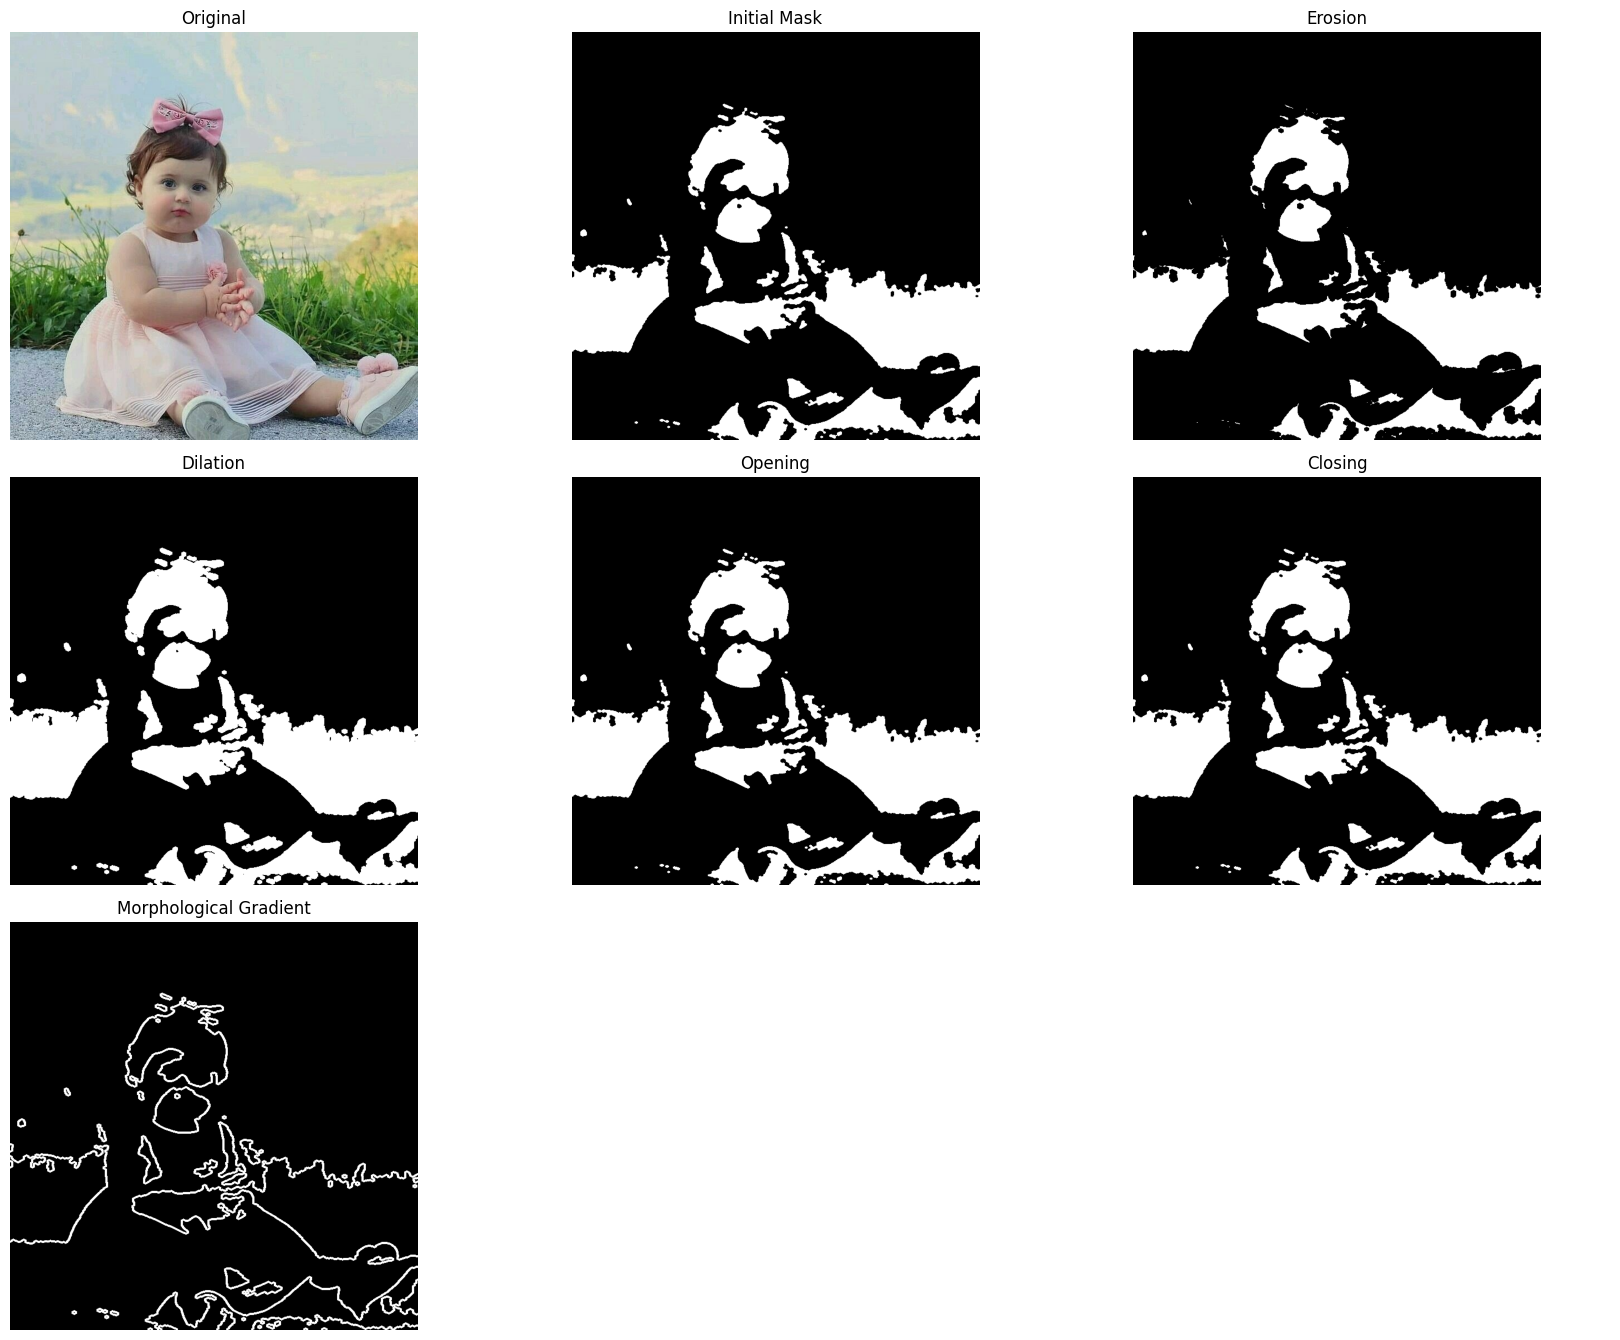

In [12]:
foreground_mask = prepare_foreground_mask(image)
morphology = morphology_results(
    foreground_mask,
    kernel_size=5,
    iterations=1,
    shape='ellipse'
)

morphology_display = {
    'Original': image,
    'Initial Mask': foreground_mask
}
morphology_display.update(morphology)

show_comparison(
    morphology_display,
    columns=3,
    figure_width=17
)

### وظيفة كل عملية مورفولوجية

| العملية | الاستخدام العملي |
|---|---|
| Erosion | تقليص المناطق البيضاء وفصل العناصر المتلامسة |
| Dilation | توسيع المناطق البيضاء وربط الأجزاء القريبة |
| Opening | إزالة النقاط البيضاء الصغيرة: Erosion ثم Dilation |
| Closing | سد الثقوب والفجوات الصغيرة: Dilation ثم Erosion |
| Gradient | استخراج حدود المناطق البيضاء |

الجزء الأبيض في القناع هو العنصر الذي تتم معالجته، والأسود هو الخلفية.

## 13. اكتشاف العناصر وعزل أكبر عنصر وإزالة الخلفية

Detected objects: 10
Largest object area: 45658.50 pixels


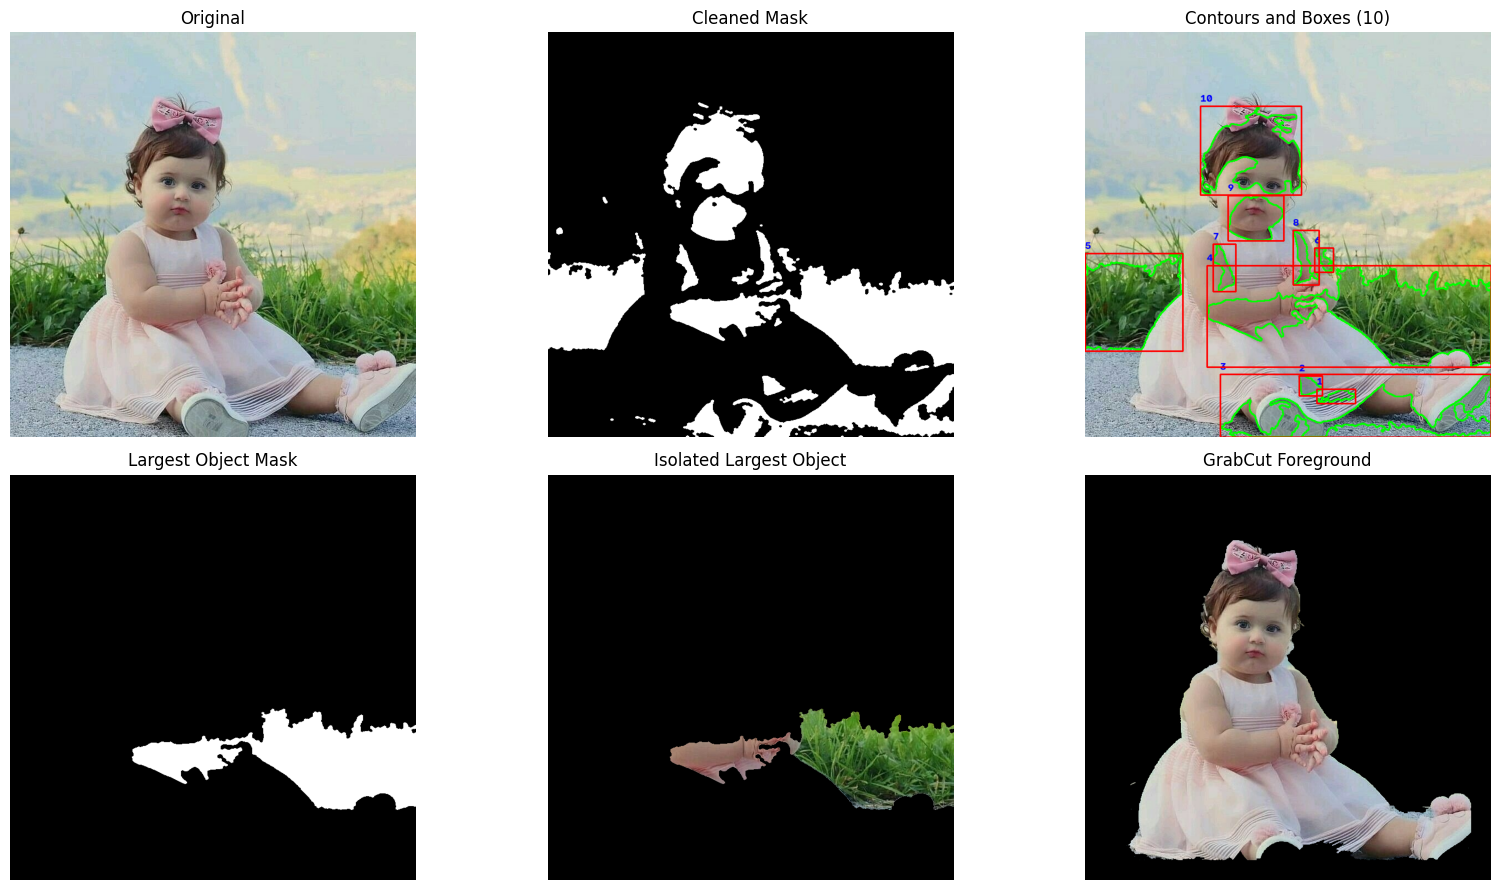

In [13]:
contour_result, object_count, cleaned_mask, contours = detect_contours(
    image, minimum_area=500
)
largest_object, largest_mask, largest_area = isolate_largest_object(
    image, cleaned_mask
)

try:
    grabcut_result, grabcut_mask = grabcut_foreground(
        image, margin_ratio=0.05, iterations=3
    )
    grabcut_status = 'GrabCut Foreground'
except cv2.error as error:
    grabcut_result = np.zeros_like(image)
    grabcut_mask = np.zeros(image.shape[:2], dtype=np.uint8)
    grabcut_status = 'GrabCut could not separate foreground'
    print('GrabCut warning:', error)

print('Detected objects:', object_count)
print(f'Largest object area: {largest_area:.2f} pixels')

show_comparison(
    {
        'Original': image,
        'Cleaned Mask': cleaned_mask,
        f'Contours and Boxes ({object_count})': contour_result,
        'Largest Object Mask': largest_mask,
        'Isolated Largest Object': largest_object,
        grabcut_status: grabcut_result
    },
    columns=3,
    figure_width=17
)

## 14. معالجة جميع الصور وحفظ النتائج

ستُحفظ كل صورة في مجلد مستقل داخل:

`04_Outputs/Images/05_Image_Segmentation_Morphology/اسم_الصورة/`

الصور الأصلية لا تُحذف ولا تُعدّل.

In [14]:
saved_files = []
processing_summary = []

for file_name, source_image in uploaded_images.items():
    stem = Path(file_name).stem
    image_output_dir = OUTPUT_DIR / stem
    image_output_dir.mkdir(parents=True, exist_ok=True)

    source_gray = cv2.cvtColor(source_image, cv2.COLOR_BGR2GRAY)
    source_variants = threshold_variants(source_image, 127)
    source_otsu_value, source_otsu = otsu_threshold(source_image)
    source_adaptive_mean, source_adaptive_gaussian = adaptive_thresholds(
        source_image, 11, 2
    )
    source_hsv_mask, source_hsv_result = hsv_color_mask(source_image)
    source_kmeans = kmeans_segmentation(source_image, clusters=3)
    source_foreground_mask = prepare_foreground_mask(source_image)
    source_morphology = morphology_results(source_foreground_mask, 5, 1)
    source_contours, source_object_count, _, _ = detect_contours(
        source_image, source_foreground_mask, minimum_area=500
    )
    source_largest, source_largest_mask, source_largest_area = (
        isolate_largest_object(source_image, source_foreground_mask)
    )

    try:
        source_grabcut, source_grabcut_mask = grabcut_foreground(
            source_image, 0.05, 3
        )
    except cv2.error:
        source_grabcut = np.zeros_like(source_image)
        source_grabcut_mask = np.zeros(
            source_image.shape[:2], dtype=np.uint8
        )

    results = {
        '00_original.png': source_image,
        '01_grayscale.png': source_gray,
        '02_binary.png': source_variants['Binary'],
        '03_binary_inverse.png': source_variants['Binary Inverse'],
        '04_otsu.png': source_otsu,
        '05_adaptive_mean.png': source_adaptive_mean,
        '06_adaptive_gaussian.png': source_adaptive_gaussian,
        '07_hsv_mask.png': source_hsv_mask,
        '08_hsv_isolated.png': source_hsv_result,
        '09_kmeans_k3.png': source_kmeans,
        '10_foreground_mask.png': source_foreground_mask,
        '11_erosion.png': source_morphology['Erosion'],
        '12_dilation.png': source_morphology['Dilation'],
        '13_opening.png': source_morphology['Opening'],
        '14_closing.png': source_morphology['Closing'],
        '15_morphological_gradient.png': (
            source_morphology['Morphological Gradient']
        ),
        '16_contours_boxes.png': source_contours,
        '17_largest_object_mask.png': source_largest_mask,
        '18_largest_object.png': source_largest,
        '19_grabcut_mask.png': source_grabcut_mask,
        '20_grabcut_foreground.png': source_grabcut
    }

    for output_name, result_image in results.items():
        output_path = image_output_dir / output_name
        if not cv2.imwrite(str(output_path), result_image):
            raise IOError(f'فشل حفظ الصورة: {output_path}')
        saved_files.append(output_path)

    processing_summary.append({
        'file': file_name,
        'otsu': source_otsu_value,
        'objects': source_object_count,
        'largest_area': source_largest_area
    })

print(f'تمت معالجة {len(uploaded_images)} صورة.')
print(f'تم حفظ {len(saved_files)} ملفًا بنجاح.')
print('مجلد النتائج:', OUTPUT_DIR)
print('\nProcessing summary:')
for item in processing_summary:
    print(
        f"- {item['file']}: Otsu={item['otsu']:.2f}, "
        f"objects={item['objects']}, "
        f"largest area={item['largest_area']:.2f}"
    )

تمت معالجة 4 صورة.
تم حفظ 84 ملفًا بنجاح.
مجلد النتائج: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/04_Outputs/Images/05_Image_Segmentation_Morphology

Processing summary:
- R.jpeg: Otsu=143.00, objects=10, largest area=45658.50
- balloons.jpg: Otsu=141.00, objects=1, largest area=155597.00
- children.jpeg: Otsu=114.00, objects=13, largest area=357616.00
- coins.jpg: Otsu=157.00, objects=7, largest area=12317.00


## 15. الربط بتطبيق Android

| Python في Colab | OpenCV Android/Java | الاستخدام في التطبيق |
|---|---|---|
| `cv2.threshold` | `Imgproc.threshold` | العتبة العادية وOtsu |
| `cv2.adaptiveThreshold` | `Imgproc.adaptiveThreshold` | معالجة اختلاف الإضاءة |
| `cv2.inRange` | `Core.inRange` | إنشاء قناع HSV لعزل لون |
| `cv2.kmeans` | `Core.kmeans` | تقسيم الصورة إلى مجموعات لونية |
| `cv2.erode` | `Imgproc.erode` | تقليص القناع |
| `cv2.dilate` | `Imgproc.dilate` | توسيع القناع |
| `cv2.morphologyEx` | `Imgproc.morphologyEx` | Opening وClosing وGradient |
| `cv2.findContours` | `Imgproc.findContours` | اكتشاف العناصر |
| `cv2.boundingRect` | `Imgproc.boundingRect` | رسم صندوق حول العنصر |
| `cv2.grabCut` | `Imgproc.grabCut` | عزل مقدمة الصورة |

كل هذه العمليات محلية ويمكن تشغيلها داخل تطبيق Android دون اتصال بالإنترنت.

## 16. أسئلة للمناقشة والتقرير

1. لماذا قد تفشل العتبة الثابتة عندما تكون الإضاءة غير متساوية؟
2. كيف يختار Otsu قيمة العتبة تلقائيًا؟
3. ما الفرق بين Opening وClosing؟
4. لماذا يكون HSV أنسب من BGR لعزل لون محدد؟
5. ماذا يحدث عند زيادة قيمة `K` في K-Means؟
6. كيف يؤثر `minimum_area` على عدد العناصر المكتشفة؟
7. ما الفرق بين العزل بالقناع اللوني والعزل باستخدام GrabCut؟

> بعد التأكد من حفظ النتائج، يمكن استخدام `Edit → Clear all outputs` قبل إغلاق الدفتر لتقليل حجمه وتسريع حفظه مع الإنترنت البطيء.

**الخطوة التالية:** الدفتر `06_Video_Processing.ipynb` لمعالجة الفيديو إطارًا بإطار وحفظ الفيديو الناتج.